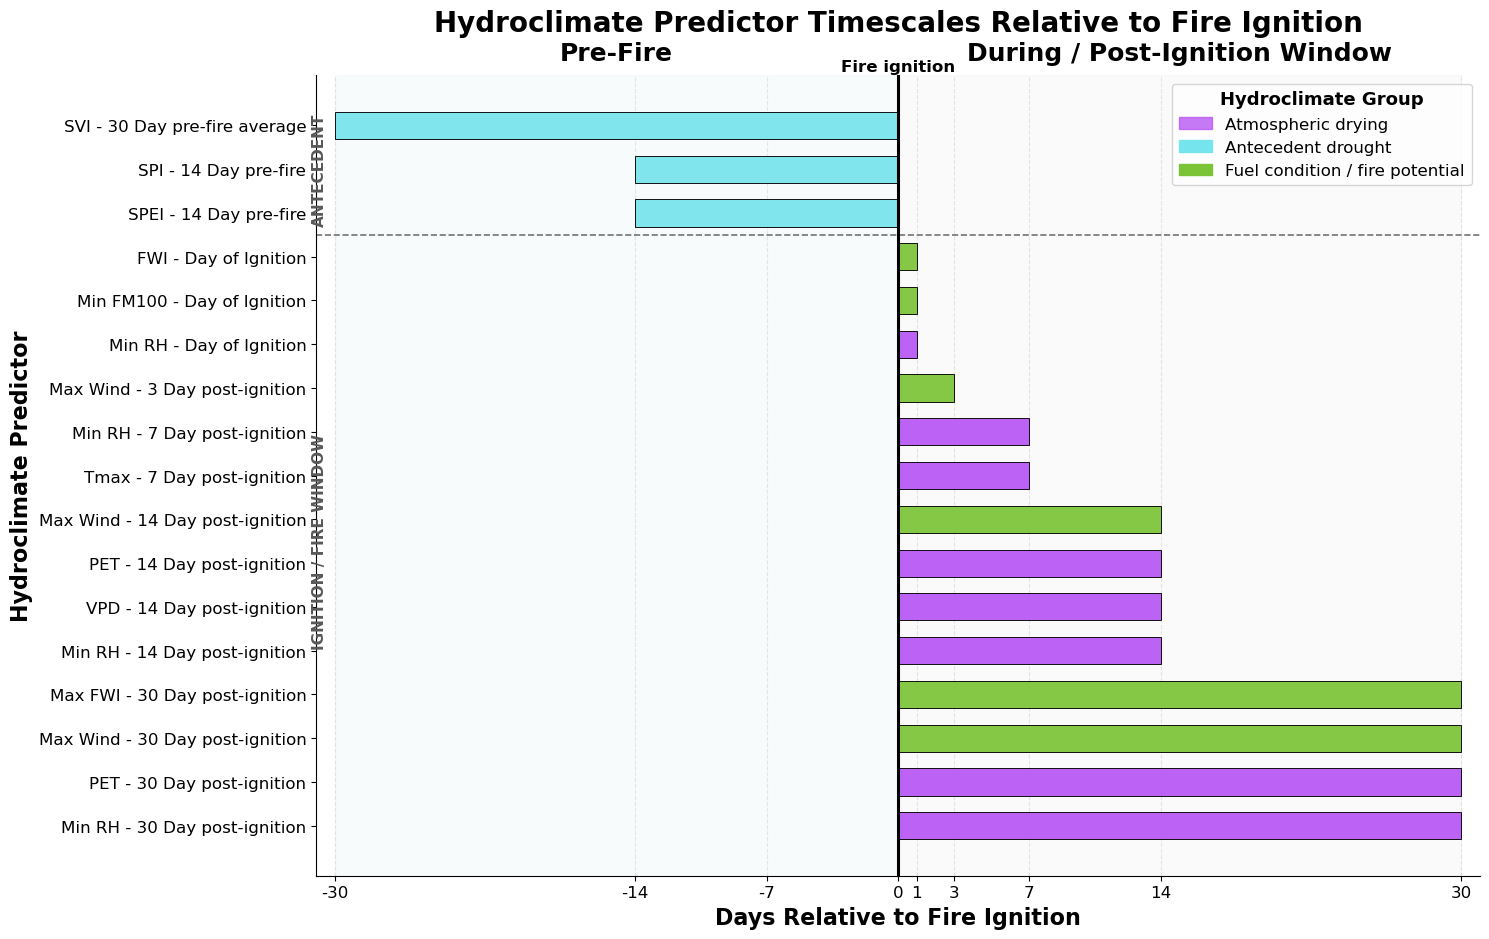

In [9]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np


# ============================================================
# 1. PREDICTOR TIMING DEFINITIONS
#
# start_day, end_day
#
# PRE-FIRE:
# negative days leading up to ignition
#
# DURING / POST-IGNITION:
# begins at ignition (day 0) and extends forward
# ============================================================

predictor_windows = {

    # ========================================================
    # PRE-FIRE / ANTECEDENT
    # ========================================================
    "SVI - 30 Day pre-fire average": (-30, 0),
    "SPI - 14 Day pre-fire": (-14, 0),
    "SPEI - 14 Day pre-fire": (-14, 0),

    # ========================================================
    # DAY OF IGNITION / DURING-FIRE
    # ========================================================
    "FWI - Day of Ignition": (0, 1),
    "Min FM100 - Day of Ignition": (0, 1),
    "Min RH - Day of Ignition": (0, 1),

    # ========================================================
    # 3-DAY WINDOW
    # ========================================================
    "Max Wind - 3 Day post-ignition": (0, 3),

    # ========================================================
    # 7-DAY WINDOW
    # ========================================================
    "Min RH - 7 Day post-ignition": (0, 7),
    "Tmax - 7 Day post-ignition": (0, 7),

    # ========================================================
    # 14-DAY WINDOW
    # ========================================================
    "Max Wind - 14 Day post-ignition": (0, 14),
    "PET - 14 Day post-ignition": (0, 14),
    "VPD - 14 Day post-ignition": (0, 14),
    "Min RH - 14 Day post-ignition": (0, 14),

    # ========================================================
    # 30-DAY WINDOW
    # ========================================================
    "Max FWI - 30 Day post-ignition": (0, 30),
    "Max Wind - 30 Day post-ignition": (0, 30),
    "PET - 30 Day post-ignition": (0, 30),
    "Min RH - 30 Day post-ignition": (0, 30),
}


# ============================================================
# 2. HYDROCLIMATE GROUPS
#
# SAME GROUP NAMES AS FIGURE 2
# ============================================================

group_map = {

    # --------------------------------------------------------
    # ANTECEDENT DROUGHT
    # --------------------------------------------------------
    "SVI - 30 Day pre-fire average": "Antecedent drought",
    "SPI - 14 Day pre-fire": "Antecedent drought",
    "SPEI - 14 Day pre-fire": "Antecedent drought",

    # --------------------------------------------------------
    # FUEL CONDITION / FIRE POTENTIAL
    # --------------------------------------------------------
    "FWI - Day of Ignition": "Fuel condition / fire potential",
    "Min FM100 - Day of Ignition": "Fuel condition / fire potential",
    "Max Wind - 3 Day post-ignition": "Fuel condition / fire potential",
    "Max Wind - 14 Day post-ignition": "Fuel condition / fire potential",
    "Max Wind - 30 Day post-ignition": "Fuel condition / fire potential",
    "Max FWI - 30 Day post-ignition": "Fuel condition / fire potential",

    # --------------------------------------------------------
    # ATMOSPHERIC DRYING
    # --------------------------------------------------------
    "Min RH - Day of Ignition": "Atmospheric drying",
    "Min RH - 7 Day post-ignition": "Atmospheric drying",
    "Tmax - 7 Day post-ignition": "Atmospheric drying",
    "Min RH - 14 Day post-ignition": "Atmospheric drying",
    "PET - 14 Day post-ignition": "Atmospheric drying",
    "VPD - 14 Day post-ignition": "Atmospheric drying",
    "Min RH - 30 Day post-ignition": "Atmospheric drying",
    "PET - 30 Day post-ignition": "Atmospheric drying",
}


# ============================================================
# 3. COLORS
#
# MATCH FIGURE 2
# ============================================================

group_colors = {
    "Atmospheric drying": "#B755F4C8",
    "Antecedent drought": "#76E4EC",
    "Fuel condition / fire potential": "#7BC437",
}


# ============================================================
# 4. ROW ORDER
#
# PRE-FIRE:
# LONGEST -> SHORTEST
#
# DURING / POST-IGNITION:
# SHORTEST -> LONGEST
# ============================================================

row_order = [

    # PRE-FIRE
    "SVI - 30 Day pre-fire average",
    "SPI - 14 Day pre-fire",
    "SPEI - 14 Day pre-fire",

    # 1 DAY
    "FWI - Day of Ignition",
    "Min FM100 - Day of Ignition",
    "Min RH - Day of Ignition",

    # 3 DAY
    "Max Wind - 3 Day post-ignition",

    # 7 DAY
    "Min RH - 7 Day post-ignition",
    "Tmax - 7 Day post-ignition",

    # 14 DAY
    "Max Wind - 14 Day post-ignition",
    "PET - 14 Day post-ignition",
    "VPD - 14 Day post-ignition",
    "Min RH - 14 Day post-ignition",

    # 30 DAY
    "Max FWI - 30 Day post-ignition",
    "Max Wind - 30 Day post-ignition",
    "PET - 30 Day post-ignition",
    "Min RH - 30 Day post-ignition",
]


# ============================================================
# 5. CREATE FIGURE
# ============================================================

fig, ax = plt.subplots(figsize=(15, 9.5))

y_positions = np.arange(len(row_order))[::-1]
bar_height = 0.62


# ============================================================
# 6. DRAW PREDICTOR WINDOWS
# ============================================================

for y, label in zip(y_positions, row_order):

    group = group_map[label]
    color = group_colors[group]
    start, end = predictor_windows[label]
    width = end - start

    ax.barh(
        y=y,
        width=width,
        left=start,
        height=bar_height,
        color=color,
        edgecolor="black",
        linewidth=0.7,
        alpha=0.92,
        zorder=3
    )


# ============================================================
# 7. FIRE IGNITION LINE
# ============================================================

ax.axvline(
    0,
    color="black",
    linewidth=2.2,
    linestyle="-",
    zorder=6
)

ax.text(
    0,
    len(row_order) + 0.18,
    "Fire ignition",
    ha="center",
    va="bottom",
    fontsize=12,
    fontweight="bold"
)


# ============================================================
# 8. BACKGROUND SHADING
# ============================================================

# Pre-fire
ax.axvspan(
    -30,
    0,
    color="#EAF4F8",
    alpha=0.32,
    zorder=0
)

# During / post-ignition
ax.axvspan(
    0,
    30,
    color="#F2F2F2",
    alpha=0.35,
    zorder=0
)


# ============================================================
# 9. Y AXIS
# ============================================================

ax.set_yticks(y_positions)
ax.set_yticklabels(row_order, fontsize=12)

ax.set_ylabel(
    "Hydroclimate Predictor",
    fontsize=16,
    fontweight="bold"
)


# ============================================================
# 10. X AXIS
# ============================================================

ax.set_xlim(-31, 31)

ax.set_xticks([-30, -14, -7, 0, 1, 3, 7, 14, 30])
ax.set_xticklabels(
    ["-30", "-14", "-7", "0", "1", "3", "7", "14", "30"],
    fontsize=12
)

ax.set_xlabel(
    "Days Relative to Fire Ignition",
    fontsize=16,
    fontweight="bold"
)


# ============================================================
# 11. PRE-FIRE / DURING-FIRE HEADERS
# ============================================================

ax.text(
    -15,
    len(row_order) + 0.65,
    "Pre-Fire",
    ha="center",
    va="center",
    fontsize=18,
    fontweight="bold"
)

ax.text(
    15,
    len(row_order) + 0.65,
    "During / Post-Ignition Window",
    ha="center",
    va="center",
    fontsize=18,
    fontweight="bold"
)


# ============================================================
# 12. DIVIDER BETWEEN PRE-FIRE AND DURING-FIRE PREDICTORS
# ============================================================

pre_fire_count = 3

divider_y = len(row_order) - pre_fire_count - 0.5

ax.axhline(
    divider_y,
    color="0.45",
    linewidth=1.2,
    linestyle="--",
    zorder=2
)


# ============================================================
# 13. SECTION LABELS
#
# Move them OFF the left axis line and slightly inward
# ============================================================

# Center of antecedent section
antecedent_center_y = np.mean(y_positions[:3])

# Center of ignition / fire-window section
fire_window_center_y = np.mean(y_positions[3:])

# Put them slightly inside the plotting area, not on the y-axis spine
section_x = -30.8

ax.text(
    section_x,
    antecedent_center_y,
    "ANTECEDENT",
    ha="center",
    va="center",
    fontsize=11,
    fontweight="bold",
    color="0.35",
    rotation=90,
    zorder=5
)

ax.text(
    section_x,
    fire_window_center_y,
    "IGNITION / FIRE WINDOW",
    ha="center",
    va="center",
    fontsize=11,
    fontweight="bold",
    color="0.35",
    rotation=90,
    zorder=5
)


# ============================================================
# 14. GRID
# ============================================================

ax.grid(
    axis="x",
    linestyle="--",
    linewidth=0.8,
    alpha=0.30,
    zorder=0
)

ax.set_axisbelow(True)


# ============================================================
# 15. GROUP LEGEND
#
# Move to TOP RIGHT
# ============================================================

legend_handles = [

    mpatches.Patch(
        color=group_colors["Atmospheric drying"],
        label="Atmospheric drying"
    ),

    mpatches.Patch(
        color=group_colors["Antecedent drought"],
        label="Antecedent drought"
    ),

    mpatches.Patch(
        color=group_colors["Fuel condition / fire potential"],
        label="Fuel condition / fire potential"
    )
]

legend = ax.legend(
    handles=legend_handles,
    loc="upper right",
    frameon=True,
    fontsize=12,
    title="Hydroclimate Group",
    title_fontsize=13
)

legend.get_title().set_fontweight("bold")


# ============================================================
# 16. STYLING
# ============================================================

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)


# ============================================================
# 17. TITLE
# ============================================================

ax.set_title(
    "Hydroclimate Predictor Timescales Relative to Fire Ignition",
    fontsize=20,
    fontweight="bold",
    pad=32
)


# ============================================================
# 18. FINAL LAYOUT
# ============================================================

plt.tight_layout()
plt.show()

In [10]:
#### RUn this before next code


import pandas as pd
import geopandas as gpd
from shapely.geometry import Point
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle

# ============================================================
# 1. LOAD FIRE DATA
# ============================================================

pdsidata = pd.read_csv(
    '/home/student/tsjohnson/Fire_Climate_Model_1984-2024_percent_pixels_km2_CONUS.txt'
)

pdsidata['Ig_Date'] = pd.to_datetime(
    pdsidata['Ig_Date'],
    errors='coerce'
)

pdsidata['year'] = pdsidata['Ig_Date'].dt.year
pdsidata['month'] = pdsidata['Ig_Date'].dt.month


# ============================================================
# 2. LOAD ECOREGIONS AND SPATIAL JOIN
# ============================================================

EPA_regions_new = gpd.read_file(
    '/home/student/tsjohnson/Ecoregions/us_eco_l3/us_eco_l3.shp'
).to_crs('EPSG:4326')

EPA_regions_new['US_L3CODE'] = (
    EPA_regions_new['US_L3CODE']
    .astype(str)
    .str.strip()
    .str.replace(r'\.0$', '', regex=True)
)


# ------------------------------------------------------------
# Convert fire coordinates to points
# ------------------------------------------------------------

pdsidata['coords'] = [
    Point(lon, lat)
    for lon, lat in zip(
        pdsidata['BurnBndLon'],
        pdsidata['BurnBndLat']
    )
]

pdsidata_points = gpd.GeoDataFrame(
    pdsidata,
    geometry='coords',
    crs='EPSG:4326'
)


# ------------------------------------------------------------
# Spatial join
# ------------------------------------------------------------

fire_ecoregion_df = gpd.sjoin(
    pdsidata_points,
    EPA_regions_new[
        [
            'US_L3CODE',
            'US_L3NAME',
            'geometry'
        ]
    ],
    predicate='intersects',
    how='left'
)


# ------------------------------------------------------------
# Keep columns needed for analysis
# ------------------------------------------------------------

fire_ecoregion_df = fire_ecoregion_df[
    [
        'BurnBndLat',
        'BurnBndLon',
        'Ig_Date',

        'High_km2',
        'Moderate_km2',
        'Low_km2',

        'High_percent',
        'Moderate_percent',

        'year',
        'month',

        'USState',
        'Event_ID',

        'US_L3CODE',
        'US_L3NAME'
    ]
].copy()


fire_ecoregion_df['US_L3CODE'] = (
    fire_ecoregion_df['US_L3CODE']
    .astype(str)
    .str.strip()
    .str.replace(r'\.0$', '', regex=True)
)


# ============================================================
# 3. DEFINE TARGET ECOREGIONS
# ============================================================

target_codes = [
    '1', '2', '3', '4', '5', '6', '7', '8', '9',
    '10', '11', '12', '13', '14', '15', '16', '17',
    '18', '19', '20', '21', '22', '23', '24', '25',
    '26', '41', '42', '43', '77', '78', '79', '80',
    '81', '85'
]


ecoregion_names = {

    '1': 'Coast Range',

    '2': 'Puget Lowland',

    '3': 'Willamette Valley',

    '4': 'Cascades',

    '5': 'Sierra Nevada',

    '6': 'Central California Foothills and Coastal Mountains',

    '7': 'Central California Valley',

    '8': 'Southern California Mountains',

    '9': 'Eastern Cascades Slopes and Foothills',

    '10': 'Columbia Plateau',

    '11': 'Blue Mountains',

    '12': 'Snake River Plain',

    '13': 'Central Basin and Range',

    '14': 'Mojave Basin and Range',

    '15': 'Northern Rockies',

    '16': 'Idaho Batholith',

    '17': 'Middle Rockies',

    '18': 'Wyoming Basin',

    '19': 'Wasatch and Uinta Mountains',

    '20': 'Colorado Plateaus',

    '21': 'Southern Rockies',

    '22': 'Arizona/New Mexico Plateau',

    '23': 'Arizona/New Mexico Mountains',

    '24': 'Chihuahuan Deserts',

    '25': 'High Plains',

    '26': 'Southwestern Tablelands',

    '41': 'Canadian Rockies',

    '42': 'Northwestern Glaciated Plains',

    '43': 'Northwestern Great Plains',

    '77': 'North Cascades',

    '78': 'Klamath Mountains/California High North Coast Range',

    '79': 'Madrean Archipelago',

    '80': 'Northern Basin and Range',

    '81': 'Sonoran Basin and Range',

    '85': 'Southern California/Northern Baja Coast'
}


fire_ecoregion_df = fire_ecoregion_df[
    fire_ecoregion_df['US_L3CODE'].isin(target_codes)
].copy()


# ============================================================
# 4. CALCULATE TOTAL ECOREGION AREA
# ============================================================

EPA_regions_area = (
    EPA_regions_new
    .to_crs('EPSG:5070')
    .copy()
)

EPA_regions_area['US_L3CODE'] = (
    EPA_regions_area['US_L3CODE']
    .astype(str)
    .str.strip()
    .str.replace(r'\.0$', '', regex=True)
)

EPA_regions_area = EPA_regions_area[
    EPA_regions_area['US_L3CODE'].isin(target_codes)
].copy()


# ------------------------------------------------------------
# Dissolve polygons by ecoregion
# ------------------------------------------------------------

ecoregion_area_df = (
    EPA_regions_area
    .dissolve(by='US_L3CODE')
    .reset_index()
)


# ------------------------------------------------------------
# m² -> km²
# ------------------------------------------------------------

ecoregion_area_df['ecoregion_area_km2'] = (
    ecoregion_area_df.geometry.area
    / 1_000_000
)

ecoregion_area_df = ecoregion_area_df[
    [
        'US_L3CODE',
        'ecoregion_area_km2'
    ]
].copy()


# ============================================================
# 5. FUNCTION:
# CHANGE BETWEEN EARLY AND LATE PERIODS
# ============================================================

def get_period_difference(df, months):

    sub = df[
        df['month'].isin(months)
    ].copy()

    sub = sub[
        (sub['year'] >= 1984)
        &
        (sub['year'] <= 2024)
    ].copy()


    # --------------------------------------------------------
    # 1984–2003
    # --------------------------------------------------------

    first = sub[
        (sub['year'] >= 1984)
        &
        (sub['year'] <= 2003)
    ].copy()


    # --------------------------------------------------------
    # 2004–2024
    # --------------------------------------------------------

    second = sub[
        (sub['year'] >= 2004)
        &
        (sub['year'] <= 2024)
    ].copy()


    # --------------------------------------------------------
    # Total severity area by ecoregion
    # --------------------------------------------------------

    first_sums = (
        first
        .groupby('US_L3CODE')[
            [
                'Moderate_km2',
                'High_km2'
            ]
        ]
        .sum()
        .reset_index()
    )


    second_sums = (
        second
        .groupby('US_L3CODE')[
            [
                'Moderate_km2',
                'High_km2'
            ]
        ]
        .sum()
        .reset_index()
    )


    # --------------------------------------------------------
    # Rename columns
    # --------------------------------------------------------

    first_sums = first_sums.rename(
        columns={
            'Moderate_km2': 'Moderate_first_km2',
            'High_km2': 'High_first_km2'
        }
    )

    second_sums = second_sums.rename(
        columns={
            'Moderate_km2': 'Moderate_second_km2',
            'High_km2': 'High_second_km2'
        }
    )


    # --------------------------------------------------------
    # Merge periods
    # --------------------------------------------------------

    merged = pd.merge(
        first_sums,
        second_sums,
        on='US_L3CODE',
        how='outer'
    )


    # --------------------------------------------------------
    # Ensure all target ecoregions exist
    # --------------------------------------------------------

    base = pd.DataFrame({
        'US_L3CODE': target_codes
    })

    merged = base.merge(
        merged,
        on='US_L3CODE',
        how='left'
    )


    fire_columns = [
        'Moderate_first_km2',
        'High_first_km2',
        'Moderate_second_km2',
        'High_second_km2'
    ]

    merged[fire_columns] = (
        merged[fire_columns]
        .fillna(0)
    )


    # --------------------------------------------------------
    # Add ecoregion area
    # --------------------------------------------------------

    merged = merged.merge(
        ecoregion_area_df,
        on='US_L3CODE',
        how='left'
    )


    missing_area = (
        merged.loc[
            merged['ecoregion_area_km2'].isna(),
            'US_L3CODE'
        ]
        .tolist()
    )

    if missing_area:

        raise ValueError(
            f'Missing ecoregion area for codes: {missing_area}'
        )


    # ========================================================
    # PERCENT OF ECOREGION AREA BURNED
    # ========================================================

    merged['Moderate_first_percent'] = (
        merged['Moderate_first_km2']
        /
        merged['ecoregion_area_km2']
    ) * 100


    merged['Moderate_second_percent'] = (
        merged['Moderate_second_km2']
        /
        merged['ecoregion_area_km2']
    ) * 100


    merged['High_first_percent'] = (
        merged['High_first_km2']
        /
        merged['ecoregion_area_km2']
    ) * 100


    merged['High_second_percent'] = (
        merged['High_second_km2']
        /
        merged['ecoregion_area_km2']
    ) * 100


    # ========================================================
    # LATE MINUS EARLY
    # ========================================================

    merged['Moderate_diff'] = (
        merged['Moderate_second_percent']
        -
        merged['Moderate_first_percent']
    )


    merged['High_diff'] = (
        merged['High_second_percent']
        -
        merged['High_first_percent']
    )


    merged['ModHigh_diff'] = (
        merged['Moderate_diff']
        +
        merged['High_diff']
    )


    merged['Ecoregion_Name'] = (
        merged['US_L3CODE']
        .map(ecoregion_names)
    )


    return merged


# ============================================================
# 6. SUMMER + FALL
#
# JUNE THROUGH NOVEMBER
# ============================================================

summer_fall_months = [
    6, 7, 8, 9, 10, 11
]


plot_df = get_period_difference(
    fire_ecoregion_df,
    months=summer_fall_months
)


# ============================================================
# 7. NUMBER OF UNIQUE SUMMER + FALL FIRES PER ECOREGION
#
# Used only for the n= labels on the plot.
# ============================================================

fire_count_df = fire_ecoregion_df[
    (
        fire_ecoregion_df['month'].isin(
            summer_fall_months
        )
    )
    &
    (
        fire_ecoregion_df['year'] >= 1984
    )
    &
    (
        fire_ecoregion_df['year'] <= 2024
    )
].copy()


fire_counts = (
    fire_count_df
    .groupby('US_L3CODE')['Event_ID']
    .nunique()
    .reset_index(
        name='n_fires'
    )
)


plot_df = plot_df.merge(
    fire_counts,
    on='US_L3CODE',
    how='left'
)


plot_df['n_fires'] = (
    plot_df['n_fires']
    .fillna(0)
    .astype(int)
)


# ============================================================
# 8. SORT ECOREGIONS
#
# GREATEST -> SMALLEST MODERATE + HIGH CHANGE
# ============================================================

plot_df = (
    plot_df
    .sort_values(
        by='ModHigh_diff',
        ascending=False
    )
    .reset_index(
        drop=True
    )
)


# ============================================================
# 9. PREPARE BAR VALUES
# ============================================================

x = np.arange(
    len(plot_df)
)


moderate_change = (
    plot_df['Moderate_diff']
    .to_numpy()
)


high_change = (
    plot_df['High_diff']
    .to_numpy()
)


stack_total = (
    moderate_change
    +
    high_change
)



US_L3CODE                                     Ecoregion_Name  midpoint_year  Moderate_diff  High_diff  ModHigh_diff
       78                                  Klamath Mountains           2002       8.929715   8.294361     17.224077
        8                      Southern California Mountains           2002       8.424986   7.518745     15.943731
        5                                      Sierra Nevada           2002       6.824785   5.023008     11.847793
       77                                     North Cascades           2002       4.860872   4.491838      9.352711
        4                                           Cascades           2002       3.619911   4.042360      7.662271
        6 Central California Foothills and Coastal Mountains           2002       4.084847   2.394636      6.479483
       16                                    Idaho Batholith           2002       4.391362   2.899696      7.291058
       85            Southern California/Northern Baja Coast           2

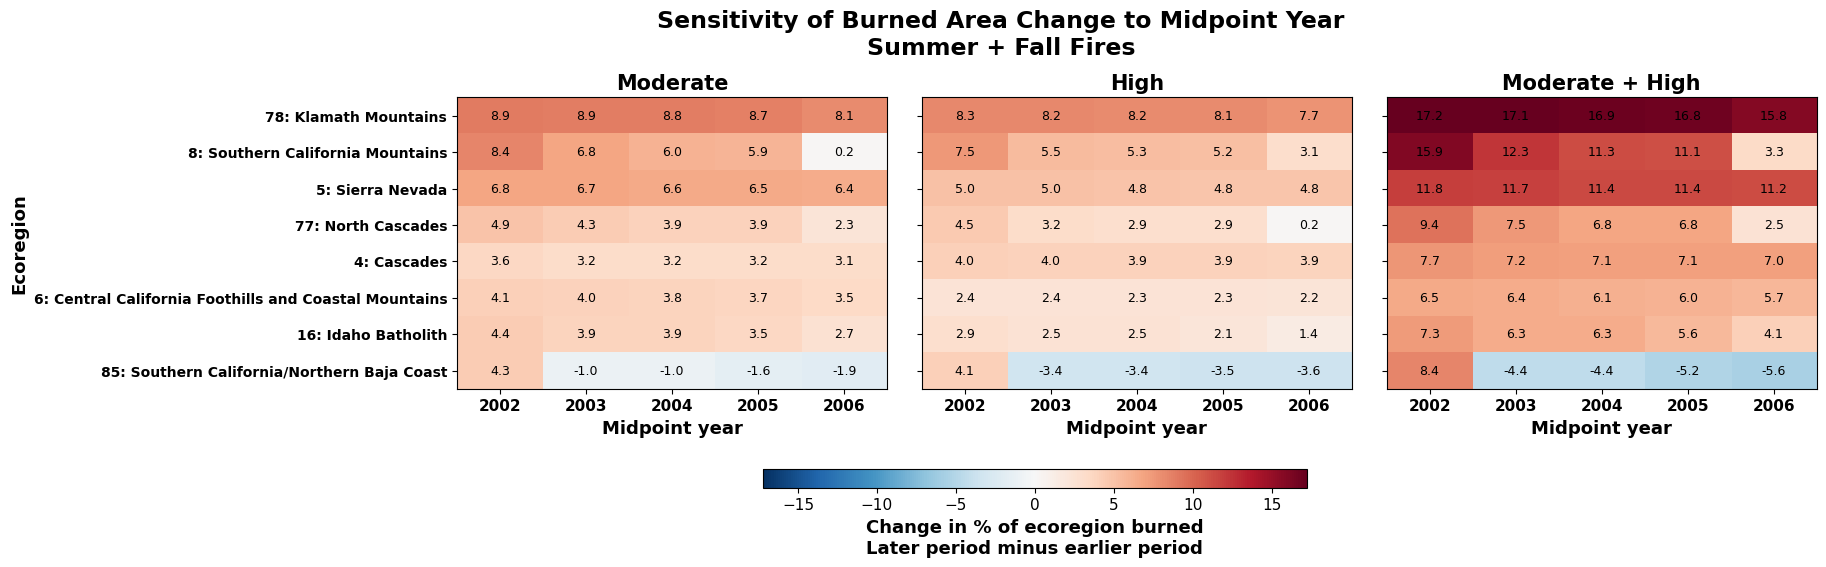

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle

# ============================================================
# 1. LOAD FIRE DATA
# ============================================================

pdsidata = pd.read_csv(
    '/home/student/tsjohnson/Fire_Climate_Model_1984-2024_percent_pixels_km2_CONUS.txt'
)

pdsidata['Ig_Date'] = pd.to_datetime(
    pdsidata['Ig_Date'],
    errors='coerce'
)

pdsidata['year'] = pdsidata['Ig_Date'].dt.year
pdsidata['month'] = pdsidata['Ig_Date'].dt.month


# ============================================================
# 2. LOAD ECOREGIONS AND SPATIAL JOIN
# ============================================================

EPA_regions_new = gpd.read_file(
    '/home/student/tsjohnson/Ecoregions/us_eco_l3/us_eco_l3.shp'
).to_crs('EPSG:4326')

EPA_regions_new['US_L3CODE'] = (
    EPA_regions_new['US_L3CODE']
    .astype(str)
    .str.strip()
    .str.replace(r'\.0$', '', regex=True)
)


# ------------------------------------------------------------
# Convert fire coordinates to points
# ------------------------------------------------------------

pdsidata['coords'] = [
    Point(lon, lat)
    for lon, lat in zip(
        pdsidata['BurnBndLon'],
        pdsidata['BurnBndLat']
    )
]

pdsidata_points = gpd.GeoDataFrame(
    pdsidata,
    geometry='coords',
    crs='EPSG:4326'
)


# ------------------------------------------------------------
# Spatial join
# ------------------------------------------------------------

fire_ecoregion_df = gpd.sjoin(
    pdsidata_points,
    EPA_regions_new[
        [
            'US_L3CODE',
            'US_L3NAME',
            'geometry'
        ]
    ],
    predicate='intersects',
    how='left'
)


# ------------------------------------------------------------
# Keep columns needed for analysis
# ------------------------------------------------------------

fire_ecoregion_df = fire_ecoregion_df[
    [
        'BurnBndLat',
        'BurnBndLon',
        'Ig_Date',

        'High_km2',
        'Moderate_km2',
        'Low_km2',

        'High_percent',
        'Moderate_percent',

        'year',
        'month',

        'USState',
        'Event_ID',

        'US_L3CODE',
        'US_L3NAME'
    ]
].copy()


fire_ecoregion_df['US_L3CODE'] = (
    fire_ecoregion_df['US_L3CODE']
    .astype(str)
    .str.strip()
    .str.replace(r'\.0$', '', regex=True)
)
# ============================================================
# 1. UPDATED ECOREGIONS OF INTEREST
#
# SAME ORDER AS FIGURES 2 AND 3
# ============================================================

target_codes = [
    "78",
    "8",
    "5",
    "77",
    "4",
    "6",
    "16",
    "85"
]


# ============================================================
# 2. ECOREGION NAMES
# ============================================================

ecoregion_names = {

    "78":
        "Klamath Mountains",

    "8":
        "Southern California Mountains",

    "5":
        "Sierra Nevada",

    "77":
        "North Cascades",

    "4":
        "Cascades",

    "6":
        "Central California Foothills and Coastal Mountains",

    "16":
        "Idaho Batholith",

    "85":
        "Southern California/Northern Baja Coast"
}


# ============================================================
# 3. SENSITIVITY SETTINGS
# ============================================================

midpoint_years = [
    2002,
    2003,
    2004,
    2005,
    2006
]


# Summer + Fall:
# June through November
months_to_use = [
    6,
    7,
    8,
    9,
    10,
    11
]


# ============================================================
# 4. HELPER:
# CALCULATE LATER - EARLIER FOR ONE MIDPOINT
# ============================================================

def get_midpoint_difference(
    df,
    midpoint_year,
    months
):


    # --------------------------------------------------------
    # Keep only selected months
    # --------------------------------------------------------

    sub = df[

        df[
            "month"
        ]

        .isin(
            months
        )

    ].copy()


    # --------------------------------------------------------
    # Keep only focal regions
    # --------------------------------------------------------

    sub["US_L3CODE"] = (

        sub[
            "US_L3CODE"
        ]

        .astype(str)

        .str.strip()

        .str.replace(
            r"\.0$",
            "",
            regex=True
        )
    )


    sub = sub[

        sub[
            "US_L3CODE"
        ]

        .isin(
            target_codes
        )

    ].copy()


    # --------------------------------------------------------
    # Earlier period
    # --------------------------------------------------------

    first = sub[

        sub[
            "year"
        ]

        <= midpoint_year

    ].copy()


    # --------------------------------------------------------
    # Later period
    # --------------------------------------------------------

    second = sub[

        sub[
            "year"
        ]

        > midpoint_year

    ].copy()


    # --------------------------------------------------------
    # Total severity area by ecoregion
    # --------------------------------------------------------

    first_sums = (

        first

        .groupby(
            "US_L3CODE"
        )[
            [
                "Moderate_km2",
                "High_km2"
            ]
        ]

        .sum()

        .reset_index()
    )


    second_sums = (

        second

        .groupby(
            "US_L3CODE"
        )[
            [
                "Moderate_km2",
                "High_km2"
            ]
        ]

        .sum()

        .reset_index()
    )


    # --------------------------------------------------------
    # Rename
    # --------------------------------------------------------

    first_sums = first_sums.rename(

        columns={

            "Moderate_km2":
                "Moderate_first_km2",

            "High_km2":
                "High_first_km2"
        }
    )


    second_sums = second_sums.rename(

        columns={

            "Moderate_km2":
                "Moderate_second_km2",

            "High_km2":
                "High_second_km2"
        }
    )


    # --------------------------------------------------------
    # Merge periods
    # --------------------------------------------------------

    merged = pd.merge(

        first_sums,

        second_sums,

        on=
            "US_L3CODE",

        how=
            "outer"
    )


    # --------------------------------------------------------
    # Ensure all 8 focal regions are present
    # --------------------------------------------------------

    base = pd.DataFrame({

        "US_L3CODE":
            target_codes
    })


    merged["US_L3CODE"] = (

        merged[
            "US_L3CODE"
        ]

        .astype(str)
    )


    merged = base.merge(

        merged,

        on=
            "US_L3CODE",

        how=
            "left"
    )


    fire_cols = [

        "Moderate_first_km2",

        "High_first_km2",

        "Moderate_second_km2",

        "High_second_km2"
    ]


    merged[
        fire_cols
    ] = (

        merged[
            fire_cols
        ]

        .fillna(0)
    )


    # --------------------------------------------------------
    # Add ecoregion area
    # --------------------------------------------------------

    area_df = ecoregion_area_df.copy()


    area_df["US_L3CODE"] = (

        area_df[
            "US_L3CODE"
        ]

        .astype(str)

        .str.strip()

        .str.replace(
            r"\.0$",
            "",
            regex=True
        )
    )


    area_df = area_df[

        area_df[
            "US_L3CODE"
        ]

        .isin(
            target_codes
        )

    ].copy()


    merged = merged.merge(

        area_df,

        on=
            "US_L3CODE",

        how=
            "left"
    )


    # --------------------------------------------------------
    # Check area
    # --------------------------------------------------------

    missing_area = (

        merged.loc[

            merged[
                "ecoregion_area_km2"
            ]

            .isna(),

            "US_L3CODE"
        ]

        .tolist()
    )


    if missing_area:

        raise ValueError(

            "Missing ecoregion area for codes: "
            f"{missing_area}"
        )


    # ========================================================
    # PERCENT OF ECOREGION AREA BURNED
    # ========================================================

    merged[
        "Moderate_first_percent"
    ] = (

        merged[
            "Moderate_first_km2"
        ]

        /

        merged[
            "ecoregion_area_km2"
        ]

    ) * 100


    merged[
        "Moderate_second_percent"
    ] = (

        merged[
            "Moderate_second_km2"
        ]

        /

        merged[
            "ecoregion_area_km2"
        ]

    ) * 100


    merged[
        "High_first_percent"
    ] = (

        merged[
            "High_first_km2"
        ]

        /

        merged[
            "ecoregion_area_km2"
        ]

    ) * 100


    merged[
        "High_second_percent"
    ] = (

        merged[
            "High_second_km2"
        ]

        /

        merged[
            "ecoregion_area_km2"
        ]

    ) * 100


    merged[
        "ModHigh_first_percent"
    ] = (

        (
            merged[
                "Moderate_first_km2"
            ]

            +

            merged[
                "High_first_km2"
            ]
        )

        /

        merged[
            "ecoregion_area_km2"
        ]

    ) * 100


    merged[
        "ModHigh_second_percent"
    ] = (

        (
            merged[
                "Moderate_second_km2"
            ]

            +

            merged[
                "High_second_km2"
            ]
        )

        /

        merged[
            "ecoregion_area_km2"
        ]

    ) * 100


    # ========================================================
    # LATER MINUS EARLIER
    # ========================================================

    merged[
        "Moderate_diff"
    ] = (

        merged[
            "Moderate_second_percent"
        ]

        -

        merged[
            "Moderate_first_percent"
        ]
    )


    merged[
        "High_diff"
    ] = (

        merged[
            "High_second_percent"
        ]

        -

        merged[
            "High_first_percent"
        ]
    )


    merged[
        "ModHigh_diff"
    ] = (

        merged[
            "ModHigh_second_percent"
        ]

        -

        merged[
            "ModHigh_first_percent"
        ]
    )


    # --------------------------------------------------------
    # Add midpoint + names
    # --------------------------------------------------------

    merged[
        "midpoint_year"
    ] = midpoint_year


    merged[
        "Ecoregion_Name"
    ] = (

        merged[
            "US_L3CODE"
        ]

        .map(
            ecoregion_names
        )
    )


    return merged


# ============================================================
# 5. RUN SENSITIVITY ANALYSIS
# ============================================================

sensitivity_list = []


for midpoint in midpoint_years:


    tmp = get_midpoint_difference(

        fire_ecoregion_df,

        midpoint_year=
            midpoint,

        months=
            months_to_use
    )


    sensitivity_list.append(
        tmp
    )


sensitivity_df = pd.concat(

    sensitivity_list,

    ignore_index=
        True
)


# ============================================================
# 6. INSPECT VALUES
# ============================================================

print(

    sensitivity_df[
        [
            "US_L3CODE",
            "Ecoregion_Name",
            "midpoint_year",
            "Moderate_diff",
            "High_diff",
            "ModHigh_diff"
        ]
    ]

    .to_string(
        index=False
    )
)


# ============================================================
# 7. HEATMAP LABELS
# ============================================================

xtick_labels = [

    str(
        year
    )

    for year in midpoint_years
]


ytick_labels = [

    f"{code}: {ecoregion_names[code]}"

    for code in target_codes
]


plot_vars = {

    "Moderate":
        "Moderate_diff",

    "High":
        "High_diff",

    "Moderate + High":
        "ModHigh_diff"
}


# ============================================================
# 8. CREATE FIGURE
# ============================================================

fig, axes = plt.subplots(

    1,
    3,

    figsize=(
        17,
        5.5
    ),

    sharey=
        True
)


# ============================================================
# 9. SYMMETRIC COLOR SCALE AROUND ZERO
# ============================================================

all_vals = (

    sensitivity_df[
        [
            "Moderate_diff",
            "High_diff",
            "ModHigh_diff"
        ]
    ]

    .values

    .flatten()
)


vmax = np.nanmax(

    np.abs(
        all_vals
    )
)


# ============================================================
# 10. PLOT HEATMAPS
# ============================================================

for ax, (
    title,
    col
) in zip(

    axes,

    plot_vars.items()
):


    heat_data = (

        sensitivity_df

        .pivot(

            index=
                "US_L3CODE",

            columns=
                "midpoint_year",

            values=
                col
        )

        .reindex(

            index=
                target_codes,

            columns=
                midpoint_years
        )
    )


    im = ax.imshow(

        heat_data.values,

        aspect=
            "auto",

        cmap=
            "RdBu_r",

        vmin=
            -vmax,

        vmax=
            vmax
    )


    # --------------------------------------------------------
    # Panel title
    # --------------------------------------------------------

    ax.set_title(

        title,

        fontsize=
            15,

        fontweight=
            "bold"
    )


    # --------------------------------------------------------
    # X axis
    # --------------------------------------------------------

    ax.set_xticks(

        np.arange(
            len(
                midpoint_years
            )
        )
    )


    ax.set_xticklabels(

        xtick_labels,

        fontsize=
            11,

        fontweight=
            "bold"
    )


    ax.set_xlabel(

        "Midpoint year",

        fontsize=
            13,

        fontweight=
            "bold"
    )


    # --------------------------------------------------------
    # Y axis
    # --------------------------------------------------------

    ax.set_yticks(

        np.arange(
            len(
                target_codes
            )
        )
    )


    ax.set_yticklabels(

        ytick_labels,

        fontsize=
            10,

        fontweight=
            "bold"
    )


    # --------------------------------------------------------
    # Add values inside cells
    # --------------------------------------------------------

    for i in range(
        len(
            target_codes
        )
    ):


        for j in range(
            len(
                midpoint_years
            )
        ):


            val = heat_data.values[
                i,
                j
            ]


            if np.isnan(
                val
            ):

                continue


            ax.text(

                j,
                i,

                f"{val:.1f}",

                ha=
                    "center",

                va=
                    "center",

                fontsize=
                    9,

                color=
                    "black"
            )


# ============================================================
# 11. Y LABEL
# ============================================================

axes[
    0
].set_ylabel(

    "Ecoregion",

    fontsize=
        13,

    fontweight=
        "bold"
)


# ============================================================
# 12. MAIN TITLE
# ============================================================

fig.suptitle(

    "Sensitivity of Burned Area Change to Midpoint Year\n"
    "Summer + Fall Fires",

    fontsize=
        17,

    fontweight=
        "bold",

    y=
        0.96
)


# ============================================================
# 13. LAYOUT
# ============================================================

fig.subplots_adjust(

    left=
        0.18,

    right=
        0.98,

    top=
        0.80,

    bottom=
        0.27,

    wspace=
        0.08
)


# ============================================================
# 14. COLORBAR
# ============================================================

cbar_ax = fig.add_axes(
    [
        0.36,
        0.09,
        0.32,
        0.035
    ]
)


cbar = fig.colorbar(

    im,

    cax=
        cbar_ax,

    orientation=
        "horizontal"
)


cbar.set_label(

    "Change in % of ecoregion burned\n"
    "Later period minus earlier period",

    fontsize=
        13,

    fontweight=
        "bold"
)


cbar.ax.tick_params(
    labelsize=11
)


# ============================================================
# 15. SHOW
# ============================================================

plt.show()